# Experiment 2: Email Spam/Ham Classification using Naive Bayes and KNN
Source: `experiment.org` (Org Babel); this notebook is the executed Jupyter version.


**Sri Sivasubramaniya Nadar College of Engineering, Chennai**  
*(An Autonomous Institution Affiliated to Anna University)*  
ICS1512 — Machine Learning Algorithms Laboratory


| Field | Value |
|---|---|
| Experiment No. | 2 |
| Experiment Title | Email Spam/Ham Classification using Naive Bayes and KNN |
| Student Name | Emmanuel Maximus Ravichandran |
| Register Number | 3122247001015 |
| Faculty | Dr. Poreddy Ajay Kumar Reddy |
| Submission Date |  |

## Objective


To build spam classifiers using Naive Bayes and K-Nearest Neighbours (KNN); to compare the
Gaussian, Multinomial and Bernoulli Naive Bayes variants; to study the effect of varying k;
to compare KDTree and BallTree neighbour search; to optimise KNN with GridSearchCV and
RandomizedSearchCV; to evaluate computational complexity and execution time; and to evaluate
the models with 5-fold cross-validation.

## Problem Statement


Given the 57 numeric word-frequency, character-frequency and capital-letter features of an
email, classify the email as spam (1) or ham (0). The input is a 57-dimensional feature
vector, the output is a binary label, and the objective is to compare probabilistic (Naive
Bayes) and instance-based (KNN) classifiers on accuracy, precision, recall, F1-score and
ROC-AUC, and on training and prediction time.

## Dataset Description


| Dataset Name | Spambase |
|---|---|
| Dataset Source | UCI Machine Learning Repository (id 94), also on Kaggle |
| Number of Samples | 4601 (2788 ham, 1813 spam) |
| Number of Features | 57 (48 word frequencies, 6 character frequencies, 3 capital-run statistics) |
| Number of Classes | 2 (ham = 0, spam = 1) |
| Missing Values | 0 |
| Train-Test Split | 75 / 25, stratified (3450 train / 1151 test) |

## Exploratory Data Analysis

### Setup and Imports

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os, re, time, platform, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from scipy.stats import randint
from sklearn.model_selection import (train_test_split, GridSearchCV, RandomizedSearchCV,
                                     StratifiedKFold, cross_val_score)
from sklearn.preprocessing import StandardScaler, MinMaxScaler, Binarizer
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, precision_recall_curve,
                             confusion_matrix, ConfusionMatrixDisplay)
os.makedirs("figures", exist_ok=True)
sns.set_style("whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("setup complete")

setup complete


### Load Dataset

In [2]:
names = [re.match(r"^([\w#;()\[\]!$]+):", l).group(1) for l in open("data/spambase.names") if re.match(r"^(word|char|capital)", l)]
df = pd.read_csv("data/spambase.data", header=None, names=names + ["class"])
print("Shape:", df.shape)
print(df.iloc[:5, [0, 1, 2, 54, 55, 56, 57]])

Shape: (4601, 58)
   word_freq_make  word_freq_address  word_freq_all  \
0            0.00               0.64           0.64   
1            0.21               0.28           0.50   
2            0.06               0.00           0.71   
3            0.00               0.00           0.00   
4            0.00               0.00           0.00   

   capital_run_length_average  capital_run_length_longest  \
0                       3.756                          61   
1                       5.114                         101   
2                       9.821                         485   
3                       3.537                          40   
4                       3.537                          40   

   capital_run_length_total  class  
0                       278      1  
1                      1028      1  
2                      2259      1  
3                       191      1  
4                       191      1  


*Inference:* The file loads as 4601 rows and 58 columns: 57 feature columns named from spambase.names
plus the binary class column. The features are word and character frequencies (percentages)
and capital-letter run statistics, so they are non-negative and heavily right-skewed. The
class label is 1 for spam and 0 for ham.

### Missing Values and Statistical Summary

In [3]:
print("Total missing values:", int(df.isnull().sum().sum()))
print("Duplicate rows      :", int(df.duplicated().sum()))
print("\nClass balance:\n", df["class"].value_counts().rename({0: "ham", 1: "spam"}))
print("\nSummary of the first 8 features:")
print(df.describe().T.head(8).round(3))

Total missing values: 0
Duplicate rows      : 391

Class balance:
 class
ham     2788
spam    1813
Name: count, dtype: int64

Summary of the first 8 features:
                     count   mean    std  min  25%  50%   75%    max
word_freq_make      4601.0  0.105  0.305  0.0  0.0  0.0  0.00   4.54
word_freq_address   4601.0  0.213  1.291  0.0  0.0  0.0  0.00  14.28
word_freq_all       4601.0  0.281  0.504  0.0  0.0  0.0  0.42   5.10
word_freq_3d        4601.0  0.065  1.395  0.0  0.0  0.0  0.00  42.81
word_freq_our       4601.0  0.312  0.673  0.0  0.0  0.0  0.38  10.00
word_freq_over      4601.0  0.096  0.274  0.0  0.0  0.0  0.00   5.88
word_freq_remove    4601.0  0.114  0.391  0.0  0.0  0.0  0.00   7.27
word_freq_internet  4601.0  0.105  0.401  0.0  0.0  0.0  0.00  11.11


*Inference:* There are no missing values, so no imputation is required. The summary shows that most word
frequencies have a median of 0 with a long right tail (for example `word_freq_3d` has a
maximum of 42.8 against a mean of 0.065), meaning most emails contain a given word rarely or
never. There are 391 duplicate rows; they are kept because repeated emails are genuine
observations in the original data. The class split is 2788 ham to 1813 spam (60.6% to
39.4%).

### Class Distribution

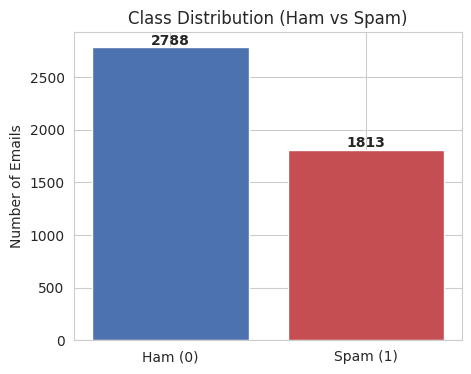

In [4]:
plt.figure(figsize=(5, 4))
counts = df["class"].value_counts().sort_index()
bars = plt.bar(["Ham (0)", "Spam (1)"], counts.values, color=["#4C72B0", "#C44E52"])
for b, v in zip(bars, counts.values):
    plt.text(b.get_x() + b.get_width() / 2, v + 20, str(v), ha="center", fontweight="bold")
plt.title("Class Distribution (Ham vs Spam)")
plt.ylabel("Number of Emails")
plt.savefig("figures/fig_01_class_distribution.png", dpi=110, bbox_inches="tight")
plt.show()

*Inference:* The classes are moderately imbalanced, with 2788 ham and 1813 spam emails, a ratio of about
1.5 to 1. This is mild enough that accuracy remains meaningful, but precision, recall and F1
are also reported because the cost of a false positive (a lost legitimate email) differs
from that of a false negative. A stratified split keeps the same ratio in the training and
test sets.

### Correlation Matrix

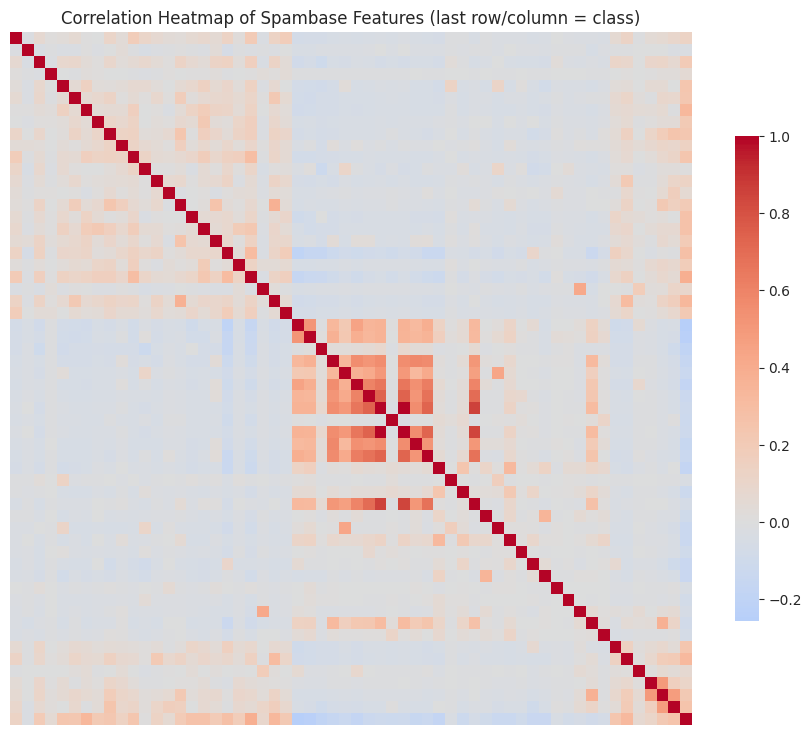

In [5]:
corr = df.corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, xticklabels=False, yticklabels=False, cbar_kws={"shrink": 0.7})
plt.title("Correlation Heatmap of Spambase Features (last row/column = class)")
plt.savefig("figures/fig_02_correlation_heatmap.png", dpi=110, bbox_inches="tight")
plt.show()

In [6]:
print("Top 10 features by absolute correlation with the class label:")
print(corr["class"].abs().sort_values(ascending=False)[1:11].round(3))
print("\nStrongest feature-feature correlation:")
c = corr.drop(index="class", columns="class").abs().where(~np.eye(57, dtype=bool))
i, j = np.unravel_index(np.nanargmax(c.values), c.shape)
print(c.index[i], "<->", c.columns[j], round(corr.iloc[i, j], 3))

Top 10 features by absolute correlation with the class label:
word_freq_your              0.383
word_freq_000               0.335
word_freq_remove            0.332
char_freq_$                 0.324
word_freq_you               0.274
word_freq_free              0.263
word_freq_business          0.263
word_freq_hp                0.257
capital_run_length_total    0.249
word_freq_our               0.242
Name: class, dtype: float64

Strongest feature-feature correlation:
word_freq_857 <-> word_freq_415 0.996


*Inference:* Most feature pairs show weak correlation, so the heatmap is mostly pale, and the class row
shows that no single feature is strongly predictive. The most correlated features with the
label are `word_freq_your` (0.383), `word_freq_000` (0.335), `word_freq_remove` (0.332) and
`char_freq_$` (0.324). The strongest feature-feature correlation is 0.996 between
`word_freq_857` and `word_freq_415`, which are phone-number fragments that occur together.
The generally low correlations mean the Naive Bayes independence assumption is not badly
violated for most features.

### Feature Distributions

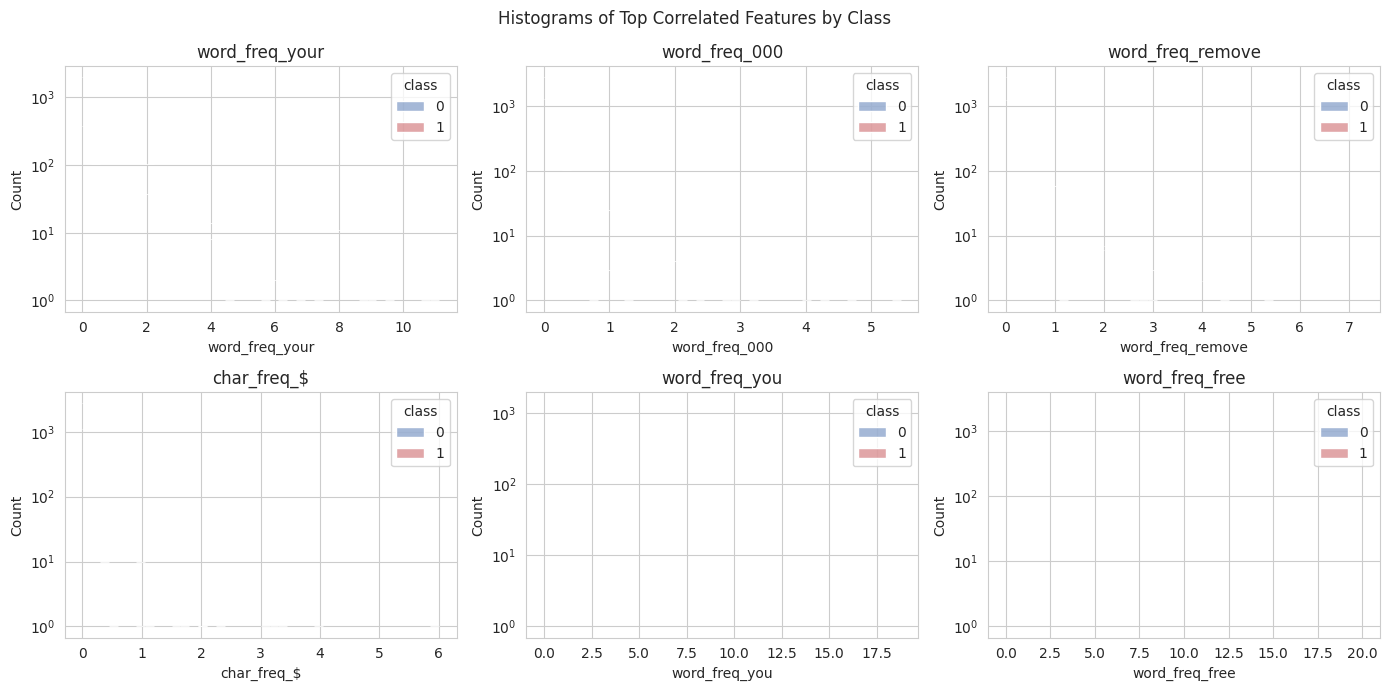

In [7]:
top_feats = corr["class"].abs().sort_values(ascending=False)[1:7].index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, feat in zip(axes.flat, top_feats):
    sns.histplot(data=df, x=feat, hue="class", bins=40, ax=ax, log_scale=(False, True), palette=["#4C72B0", "#C44E52"])
    ax.set_title(feat)
plt.suptitle("Histograms of Top Correlated Features by Class")
plt.tight_layout()
plt.savefig("figures/fig_03_histograms.png", dpi=110, bbox_inches="tight")
plt.show()

*Inference:* For all six features the spam histogram is shifted towards higher frequencies, while ham is
concentrated at zero. The log-scaled counts show that ham emails rarely use words such as
'your', 'free' or '000' and the dollar sign, while a substantial share of spam does. The
distributions are strongly skewed rather than Gaussian, which already suggests that Gaussian
Naive Bayes will fit poorly.

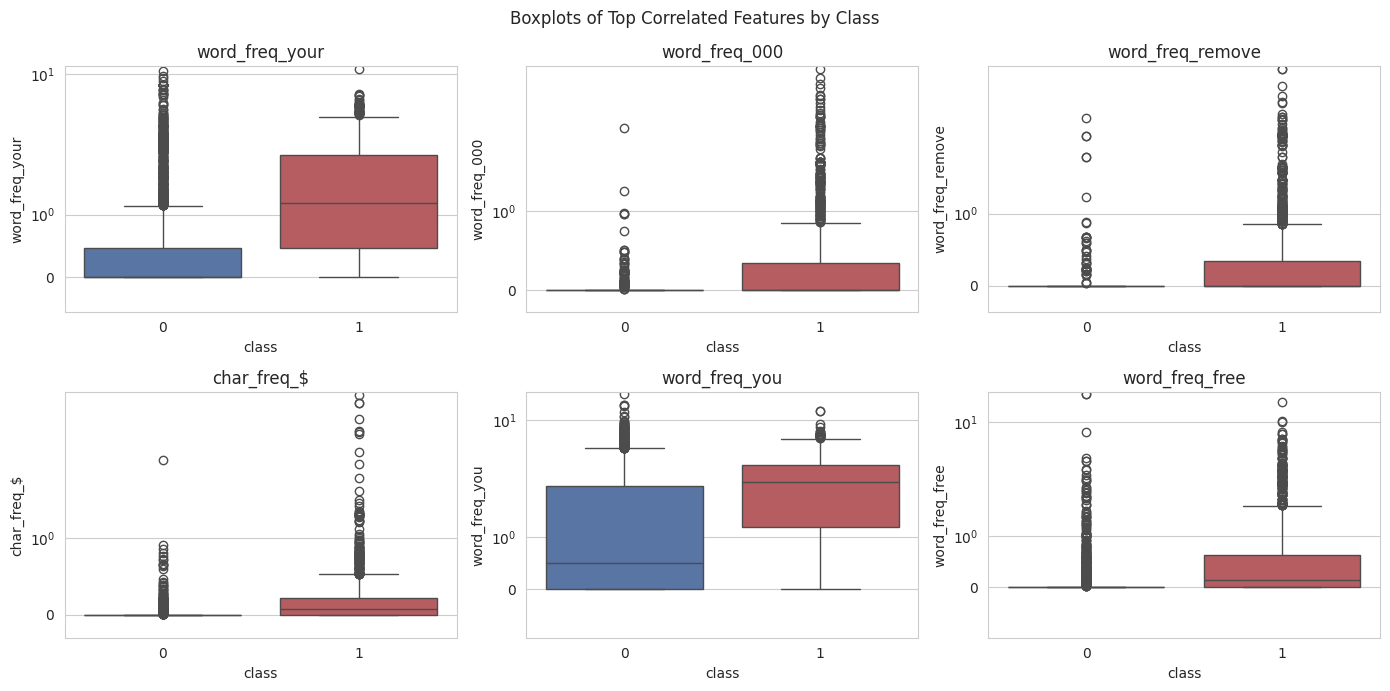

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, feat in zip(axes.flat, top_feats):
    sns.boxplot(data=df, x="class", y=feat, ax=ax, palette=["#4C72B0", "#C44E52"])
    ax.set_title(feat)
    ax.set_yscale("symlog")
plt.suptitle("Boxplots of Top Correlated Features by Class")
plt.tight_layout()
plt.savefig("figures/fig_04_boxplots.png", dpi=110, bbox_inches="tight")
plt.show()

*Inference:* The spam boxes sit above the ham boxes for each of the six features, and for ham the median
and upper quartile are often exactly zero. The symlog axis reveals many high outliers in
both classes, so the features contain extreme values. These outliers justify scaling before
KNN, since a single large feature would otherwise dominate the distance.

## Data Preprocessing


The dataset has no missing values, so no imputation is needed. The data is split 75/25 with
stratification so that both partitions keep the 60.6/39.4 class ratio. Three scaled copies
are prepared because each model family has different input requirements: standardisation
(zero mean, unit variance) for Gaussian NB and for the distance-based KNN, Min-Max scaling
to [0, 1] for Multinomial NB (which requires non-negative inputs), and binarisation (feature
present or absent) for Bernoulli NB. All scalers are fitted on the training data only to
avoid leakage.

In [9]:
X = df.drop(columns=["class"])
y = df["class"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)
scaler = StandardScaler().fit(X_train)
X_train_scaled, X_test_scaled = scaler.transform(X_train), scaler.transform(X_test)
mm = MinMaxScaler().fit(X_train)
X_train_mm, X_test_mm = mm.transform(X_train), mm.transform(X_test)
bz = Binarizer(threshold=0.0)
X_train_bin, X_test_bin = bz.fit_transform(X_train), bz.transform(X_test)
print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)
print("Train spam fraction:", round(y_train.mean(), 4), "| Test spam fraction:", round(y_test.mean(), 4))

Train shape: (3450, 57) | Test shape: (1151, 57)
Train spam fraction: 0.3939 | Test spam fraction: 0.3944


*Inference:* The 75/25 stratified split gives 3450 training and 1151 test emails, with spam fractions of
0.394 and 0.394 so both partitions represent the population. Three input versions are
prepared (standardised, Min-Max and binarised) because Gaussian NB and KNN need comparable
scales, Multinomial NB needs non-negative values and Bernoulli NB needs binary features.
Fitting the scalers on the training split only prevents information from the test set
leaking into the models.

## Machine Learning Algorithms

### Naive Bayes


Naive Bayes applies Bayes' theorem with the assumption that features are conditionally
independent given the class:

\begin{equation}
P(C \mid X) = \frac{P(X \mid C)\,P(C)}{P(X)}, \qquad
\hat{C} = \arg\max_{C}\; P(C)\prod_{j=1}^{d} P(x_j \mid C)
\end{equation}

The variants differ only in the model of $P(`x_j` \mid C)$. Gaussian NB assumes a normal
distribution with a class-specific mean and variance for each feature. Multinomial NB models
non-negative counts or frequencies with class-specific multinomial probabilities. Bernoulli
NB models binary presence or absence of each feature, and explicitly penalises absent
features. Advantages are very fast training (O(nd)), few parameters and good behaviour on
high-dimensional data; the main limitation is the independence assumption, which is violated
by correlated features.

### K-Nearest Neighbours


KNN is a lazy learner: training only stores the data, and a query is labelled by the
majority class among its k nearest training points under a distance metric (Euclidean or
Manhattan here). With distance weighting each neighbour votes with weight 1/d. KDTree and
BallTree are space-partitioning structures that reduce the cost of the neighbour search from
O(nd) for brute force to about O(log n) on average.

\begin{equation}
d_{2}(x,x') = \sqrt{\sum_{j=1}^{d}(x_j-x'_j)^2}, \qquad
d_{1}(x,x') = \sum_{j=1}^{d}\lvert x_j-x'_j\rvert
\end{equation}

Advantages are simplicity and no training phase; limitations are expensive prediction on
large datasets, sensitivity to feature scale (hence the standardisation) and degraded
neighbour quality in high dimensions.

## Experimental Setup

In [10]:
import multiprocessing
print("Python Version      :", platform.python_version())
print("Scikit-Learn Version:", sklearn.__version__)
print("NumPy / Pandas      :", np.__version__, "/", pd.__version__)
print("IDE                 : Emacs Org Babel (Org mode) and Jupyter Notebook")
print("Operating System    :", platform.system(), platform.release())
print("Hardware            :", multiprocessing.cpu_count(), "CPU core(s)")

Python Version      : 3.12.3
Scikit-Learn Version: 1.8.0
NumPy / Pandas      : 2.4.4 / 3.0.2
IDE                 : Emacs Org Babel (Org mode) and Jupyter Notebook
Operating System    : Linux 6.18.44-fc-v114
Hardware            : 1 CPU core(s)


## Hyperparameter Selection


KNN is tuned over the number of neighbours, the voting weights, the search structure and the
distance metric, using 5-fold stratified cross-validation on the training set. GridSearchCV
evaluates every combination (64 candidates), while RandomizedSearchCV samples 25 random
configurations with k drawn from 1 to 20.

| Parameter | GridSearchCV | RandomizedSearchCV |
|---|---|---|
| ~n_neighbors~ | 1, 3, 5, 7, 9, 11, 13, 15 | integer uniform on 1 to 20 |
| weights | uniform, distance | uniform, distance |
| algorithm | ~kd_tree~, ~ball_tree~ | ~kd_tree~, ~ball_tree~ |
| metric | euclidean, manhattan | euclidean, manhattan |
| Cross-validation | 5-fold stratified | 5-fold stratified |
| Candidates | 64 | 25 |

## Results

### Naive Bayes Comparison

In [11]:
def evaluate(name, model, Xtr, Xte):
    t0 = time.perf_counter(); model.fit(Xtr, y_train); tt = time.perf_counter() - t0
    t0 = time.perf_counter(); pred = model.predict(Xte); tp = time.perf_counter() - t0
    proba = model.predict_proba(Xte)[:, 1]
    return pred, proba, {"Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
                         "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
                         "ROC-AUC": roc_auc_score(y_test, proba)}
preds, probas, res = {}, {}, {}
for name, mdl, a, b in [("Gaussian", GaussianNB(), X_train_scaled, X_test_scaled),
                        ("Multinomial", MultinomialNB(), X_train_mm, X_test_mm),
                        ("Bernoulli", BernoulliNB(), X_train_bin, X_test_bin)]:
    preds[name], probas[name], res[name] = evaluate(name, mdl, a, b)
nb_table = pd.DataFrame(res).round(4)
print(nb_table)
best_nb = nb_table.loc["Accuracy"].idxmax()
print("\nBest Naive Bayes variant by accuracy:", best_nb)

           Gaussian  Multinomial  Bernoulli
Accuracy     0.8254       0.9001     0.8818
Precision    0.7077       0.9472     0.8768
Recall       0.9493       0.7907     0.8150
F1           0.8109       0.8619     0.8447
ROC-AUC      0.9368       0.9614     0.9503

Best Naive Bayes variant by accuracy: Multinomial


*Inference:* Multinomial NB is the most accurate variant (0.900), followed by Bernoulli NB (0.882) and
Gaussian NB (0.825). Gaussian NB has the highest recall (0.949) but the lowest precision
(0.708), so it catches nearly all spam at the cost of 178 false positives. Multinomial NB
reverses this trade-off, with the highest precision (0.947, only 20 false positives) and
lower recall (0.791). Multinomial NB also has the best ROC-AUC (0.961), which agrees with
the frequency-like nature of the features.

### KNN: Effect of k

In [12]:
rows = {}
knn_proba = {}
for k in [1, 3, 5, 7, 9, 11]:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train_scaled, y_train)
    p = m.predict(X_test_scaled)
    rows[k] = {"Accuracy": accuracy_score(y_test, p), "Precision": precision_score(y_test, p),
               "Recall": recall_score(y_test, p), "F1": f1_score(y_test, p)}
knn_k = pd.DataFrame(rows).T.round(4)
knn_k.index.name = "k"
print(knn_k)
print("\nBest plain KNN k by accuracy:", knn_k["Accuracy"].idxmax())

    Accuracy  Precision  Recall      F1
k                                      
1     0.8975     0.8733  0.8656  0.8695
3     0.9018     0.8814  0.8678  0.8746
5     0.8992     0.8789  0.8634  0.8711
7     0.9053     0.8929  0.8634  0.8779
9     0.9062     0.8932  0.8656  0.8792
11    0.9027     0.8904  0.8590  0.8744

Best plain KNN k by accuracy: 9


*Inference:* KNN accuracy lies in a narrow band from 0.8975 at k = 1 to 0.9062 at k = 9, so the choice of
k has only a modest effect. The best plain value is k = 9, and precision (0.893) rises
slightly with k while recall stays near 0.86. KNN with the default settings is already
better than every Naive Bayes variant on accuracy (0.906 against 0.900).

### GridSearchCV and RandomizedSearchCV

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
param_grid = {"n_neighbors": [1, 3, 5, 7, 9, 11, 13, 15], "weights": ["uniform", "distance"],
              "algorithm": ["ball_tree", "kd_tree"], "metric": ["euclidean", "manhattan"]}
t0 = time.perf_counter()
grid = GridSearchCV(KNeighborsClassifier(), param_grid, cv=cv, scoring="accuracy", n_jobs=-1).fit(X_train_scaled, y_train)
grid_time = time.perf_counter() - t0
param_dist = {"n_neighbors": randint(1, 21), "weights": ["uniform", "distance"],
              "algorithm": ["ball_tree", "kd_tree"], "metric": ["euclidean", "manhattan"]}
t0 = time.perf_counter()
rand = RandomizedSearchCV(KNeighborsClassifier(), param_dist, n_iter=25, cv=cv, scoring="accuracy",
                          random_state=RANDOM_STATE, n_jobs=-1).fit(X_train_scaled, y_train)
rand_time = time.perf_counter() - t0
def row(s, t):
    b = s.best_params_
    return {"Best k": b["n_neighbors"], "Metric": b["metric"], "Weights": b["weights"], "Algorithm": b["algorithm"],
            "CV Accuracy": round(s.best_score_, 4), "Execution Time (s)": round(t, 2)}
print(pd.DataFrame({"GridSearchCV": row(grid, grid_time), "RandomizedSearchCV": row(rand, rand_time)}))

                   GridSearchCV RandomizedSearchCV
Best k                       13                  6
Metric                manhattan          manhattan
Weights                distance           distance
Algorithm             ball_tree            kd_tree
CV Accuracy              0.9241             0.9249
Execution Time (s)        23.49              10.03


*Inference:* GridSearchCV selects k = 13 with Manhattan distance, distance weighting and the ball tree
(CV accuracy 0.9241) in roughly 20 to 25 s, while RandomizedSearchCV selects k = 6 with the
same metric and weights and a kd-tree (CV accuracy 0.9249) in roughly 10 to 12 s. Randomised
search was about twice as fast and its best score is marginally higher, because k = 6 is not
in the grid. Both searches agree on the settings that matter: Manhattan distance and
distance weighting. The tree algorithm does not change the predictions, so the choice
between them is immaterial for accuracy.

### Best Tuned KNN

In [14]:
bp = grid.best_params_
best_knn = KNeighborsClassifier(**bp)
t0 = time.perf_counter(); best_knn.fit(X_train_scaled, y_train); knn_tt = time.perf_counter() - t0
t0 = time.perf_counter(); pred_knn = best_knn.predict(X_test_scaled); knn_tp = time.perf_counter() - t0
proba_knn = best_knn.predict_proba(X_test_scaled)[:, 1]
knn_metrics = {"Accuracy": accuracy_score(y_test, pred_knn), "Precision": precision_score(y_test, pred_knn),
               "Recall": recall_score(y_test, pred_knn), "F1": f1_score(y_test, pred_knn),
               "ROC-AUC": roc_auc_score(y_test, proba_knn)}
print("Best KNN parameters:", bp)
print(pd.Series(knn_metrics).round(4).to_string())

Best KNN parameters: {'algorithm': 'ball_tree', 'metric': 'manhattan', 'n_neighbors': 13, 'weights': 'distance'}
Accuracy     0.9209
Precision    0.9504
Recall       0.8436
F1           0.8938
ROC-AUC      0.9754


*Inference:* The tuned KNN reaches 0.921 accuracy, 0.950 precision, 0.844 recall, 0.894 F1 and 0.975 ROC-
AUC on the held-out test set. This is the best result among all the models and improves on
untuned KNN (0.906) by about 1.5 points. Its recall is lower than its precision, so some
spam still passes, but only 20 legitimate emails are wrongly blocked.

### KDTree vs BallTree

In [15]:
tree = {}
for algo, label in [("kd_tree", "KDTree"), ("ball_tree", "BallTree")]:
    m = KNeighborsClassifier(n_neighbors=bp["n_neighbors"], weights=bp["weights"], metric=bp["metric"], algorithm=algo)
    t0 = time.perf_counter(); m.fit(X_train_scaled, y_train); tt = time.perf_counter() - t0
    t0 = time.perf_counter(); p = m.predict(X_test_scaled); tp = time.perf_counter() - t0
    tree[label] = {"Accuracy": round(accuracy_score(y_test, p), 4), "Training Time (s)": round(tt, 5), "Prediction Time (s)": round(tp, 4)}
print(pd.DataFrame(tree))

                      KDTree  BallTree
Accuracy             0.92090   0.92090
Training Time (s)    0.00706   0.00517
Prediction Time (s)  0.16280   0.12740


*Inference:* KDTree and BallTree give identical accuracy (0.9209), as expected because both return exact
nearest neighbours. In this run BallTree was faster to build (about 5 ms against 8 ms) and
faster to predict (about 0.13 s against 0.17 s). With 57 dimensions neither tree is very
effective, and the differences are small and subject to timing noise, so the result should
be read as a similar-performance outcome rather than a decisive win.

### 5-Fold Cross-Validation

In [16]:
nb_models = {"Gaussian": (GaussianNB(), X_train_scaled), "Multinomial": (MultinomialNB(), X_train_mm), "Bernoulli": (BernoulliNB(), X_train_bin)}
m_nb, X_nb = nb_models[best_nb]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
nb_cv = cross_val_score(m_nb, X_nb, y_train, cv=skf, scoring="accuracy")
knn_cv = cross_val_score(best_knn, X_train_scaled, y_train, cv=skf, scoring="accuracy")
cv_table = pd.DataFrame({"Naive Bayes (" + best_nb + ")": nb_cv, "Best KNN": knn_cv}, index=[1, 2, 3, 4, 5]).round(4)
cv_table.index.name = "Fold"
cv_table.loc["Average"] = cv_table.mean().round(4)
cv_table.loc["Std Dev"] = [nb_cv.std().round(4), knn_cv.std().round(4)]
print(cv_table)

         Naive Bayes (Multinomial)  Best KNN
Fold                                        
1                           0.8855    0.9130
2                           0.8971    0.9232
3                           0.8942    0.9420
4                           0.8826    0.9261
5                           0.8812    0.9159
Average                     0.8881    0.9240
Std Dev                     0.0064    0.0101


*Inference:* Over five folds the best KNN averages 0.924 accuracy with a standard deviation of 0.010, and
Multinomial NB averages 0.888 with a standard deviation of 0.006. KNN is higher in every
fold (for example 0.942 against 0.894 in fold 3), so the advantage is consistent rather than
an artefact of a single split. Naive Bayes is slightly more stable across folds, which is
typical of a low-variance model.

### Theoretical Time Complexity


| Algorithm | Training | Prediction |
|---|---|---|
| Naive Bayes | $O(nd)$ | $O(d)$ |
| KNN (Brute) | $O(1)$ | $O(nd)$ |
| KDTree | $O(n \log n)$ | $O(\log n)$ avg |
| BallTree | $O(n \log n)$ | $O(\log n)$ avg |


Here n is the number of training samples and d the number of features. Tree-based search is
efficient only when d is small; for d = 57 its advantage over brute force is expected to be
limited.

### Experimental Time Analysis

In [17]:
trows = {}
for name, mdl, a, b in [("Gaussian NB", GaussianNB(), X_train_scaled, X_test_scaled),
                        ("Multinomial NB", MultinomialNB(), X_train_mm, X_test_mm),
                        ("Bernoulli NB", BernoulliNB(), X_train_bin, X_test_bin),
                        ("Best KNN", KNeighborsClassifier(**bp), X_train_scaled, X_test_scaled)]:
    t0 = time.perf_counter(); mdl.fit(a, y_train); tt = time.perf_counter() - t0
    t0 = time.perf_counter(); mdl.predict(b); tp = time.perf_counter() - t0
    trows[name] = {"Training(s)": tt, "Prediction(s)": tp}
time_df = pd.DataFrame(trows).T.round(6)
time_df.index.name = "Algorithm"
print(time_df)

                Training(s)  Prediction(s)
Algorithm                                 
Gaussian NB        0.002667       0.001086
Multinomial NB     0.001643       0.000203
Bernoulli NB       0.002870       0.000798
Best KNN           0.005031       0.137781


*Inference:* Naive Bayes trains in 2 to 5 ms and predicts in about 1 ms or less, whereas the tuned KNN
trains in about 5 ms but needs roughly 0.15 s to predict the 1151 test emails, hundreds of
times slower than Naive Bayes. This is because KNN does its work at query time, while Naive
Bayes only evaluates a handful of per-class terms. The measurement matches the complexity
table: constant-time fitting but costly prediction for KNN, and cheap prediction for NB.

### Additional Tasks

In [18]:
print("Effect of the train-test split (best KNN parameters):")
for ts in [0.1, 0.2, 0.3, 0.4]:
    a, b, c_, d_ = train_test_split(X, y, test_size=ts, random_state=RANDOM_STATE, stratify=y)
    s = StandardScaler().fit(a)
    acc = accuracy_score(d_, KNeighborsClassifier(**bp).fit(s.transform(a), c_).predict(s.transform(b)))
    print(f"  test size {ts:.1f} (train {1-ts:.1f}): accuracy = {acc:.4f}")
print("\nEuclidean vs Manhattan distance:")
for metric in ["euclidean", "manhattan"]:
    p = KNeighborsClassifier(n_neighbors=bp["n_neighbors"], weights=bp["weights"], metric=metric).fit(X_train_scaled, y_train).predict(X_test_scaled)
    print(f"  {metric:10s}: accuracy = {accuracy_score(y_test, p):.4f}, F1 = {f1_score(y_test, p):.4f}")
print("\nWeighted KNN (uniform vs distance):")
for w in ["uniform", "distance"]:
    p = KNeighborsClassifier(n_neighbors=bp["n_neighbors"], weights=w, metric=bp["metric"]).fit(X_train_scaled, y_train).predict(X_test_scaled)
    print(f"  {w:8s}: accuracy = {accuracy_score(y_test, p):.4f}, F1 = {f1_score(y_test, p):.4f}")
print("\nOverfitting (small k) vs underfitting (large k): train / test accuracy")
for k in [1, 5, 15, 51, 151, 401]:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train_scaled, y_train)
    print(f"  k={k:3d}: train = {m.score(X_train_scaled, y_train):.4f}, test = {m.score(X_test_scaled, y_test):.4f}")

Effect of the train-test split (best KNN parameters):


  test size 0.1 (train 0.9): accuracy = 0.9046


  test size 0.2 (train 0.8): accuracy = 0.9164


  test size 0.3 (train 0.7): accuracy = 0.9247


  test size 0.4 (train 0.6): accuracy = 0.9158

Euclidean vs Manhattan distance:
  euclidean : accuracy = 0.9140, F1 = 0.8894


...

  k=  1: train = 0.9997, test = 0.8975


  k=  5: train = 0.9342, test = 0.8992
  k= 15: train = 0.9154, test = 0.8975


  k= 51: train = 0.8878, test = 0.8923


  k=151: train = 0.8672, test = 0.8601


  k=401: train = 0.8110, test = 0.8106


*Inference:* With the tuned parameters, accuracy varies between 0.905 and 0.925 across test sizes of 10%
to 40%, with no trend, so the model is stable with respect to the split proportion (the
small differences are mostly sampling variation of the test set). Manhattan distance is
better than Euclidean (0.921 against 0.914) and distance weighting is clearly better than
uniform voting (0.921 against 0.903). Training accuracy falls from 0.9997 at k = 1 to 0.811
at k = 401, while test accuracy peaks near k = 5 to 15 and falls to 0.811, so k = 1 overfits
(a gap of 0.10) and very large k underfits (both scores are low).

## Result Visualization

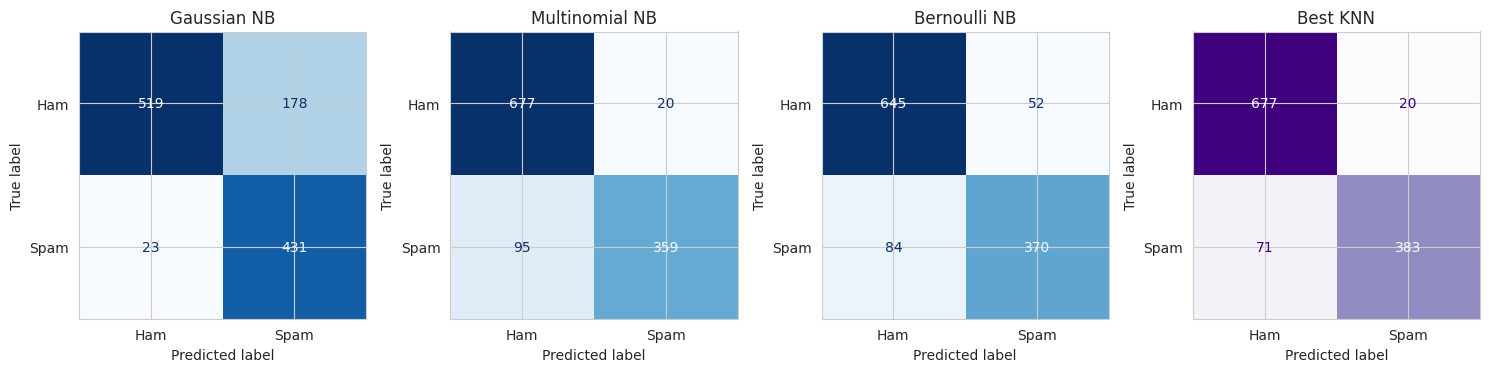

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
cms = [("Gaussian NB", preds["Gaussian"], "Blues"), ("Multinomial NB", preds["Multinomial"], "Blues"),
       ("Bernoulli NB", preds["Bernoulli"], "Blues"), ("Best KNN", pred_knn, "Purples")]
for ax, (n, p, cmap) in zip(axes, cms):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p), display_labels=["Ham", "Spam"]).plot(ax=ax, colorbar=False, cmap=cmap)
    ax.set_title(n)
plt.tight_layout()
plt.savefig("figures/fig_05_confusion_matrices.png", dpi=110, bbox_inches="tight")
plt.show()

*Inference:* The matrices show how each model errs: Gaussian NB makes 178 false positives and only 23
false negatives, Multinomial NB makes 20 false positives and 95 false negatives, Bernoulli
NB makes 52 and 84, and the tuned KNN makes 20 and 71. Multinomial NB and KNN have the same
number of false positives, but KNN misses fewer spam emails. For a spam filter the false
positives are the costlier error, which makes these two models preferable to Gaussian NB.

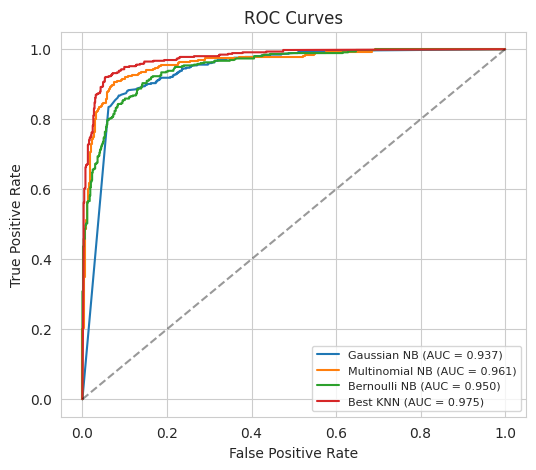

In [20]:
models = {"Gaussian NB": probas["Gaussian"], "Multinomial NB": probas["Multinomial"], "Bernoulli NB": probas["Bernoulli"], "Best KNN": proba_knn}

plt.figure(figsize=(6, 5))
for n, pr in models.items():
    f, t, _ = roc_curve(y_test, pr)
    plt.plot(f, t, label=f"{n} (AUC = {roc_auc_score(y_test, pr):.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.4)
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("ROC Curves"); plt.legend(fontsize=8)
plt.savefig("figures/fig_06_roc_curves.png", dpi=110, bbox_inches="tight")
plt.show()

*Inference:* All curves lie well above the diagonal, with AUC values of 0.975 for the tuned KNN, 0.961
for Multinomial NB, 0.950 for Bernoulli NB and 0.937 for Gaussian NB. The KNN curve
dominates in the low false-positive region that matters most for a spam filter. The ranking
by AUC is the same as the ranking by accuracy, with the exception that Gaussian NB is
competitive in the high-recall region.

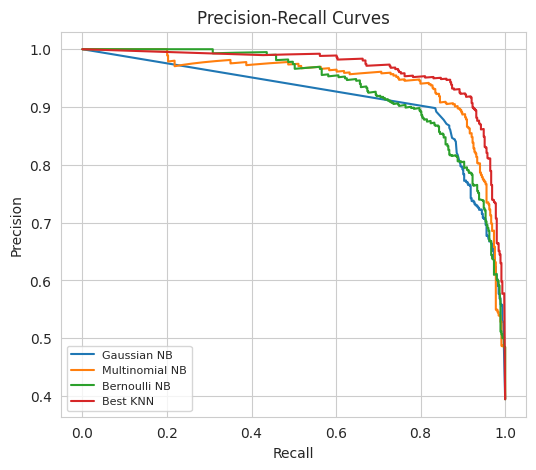

In [21]:
models = {"Gaussian NB": probas["Gaussian"], "Multinomial NB": probas["Multinomial"], "Bernoulli NB": probas["Bernoulli"], "Best KNN": proba_knn}

plt.figure(figsize=(6, 5))
for n, pr in models.items():
    p_, r_, _ = precision_recall_curve(y_test, pr)
    plt.plot(r_, p_, label=n)
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Precision-Recall Curves"); plt.legend(fontsize=8, loc="lower left")
plt.savefig("figures/fig_07_pr_curves.png", dpi=110, bbox_inches="tight")
plt.show()

*Inference:* The precision-recall curves tell the same story: the KNN curve stays at high precision for
longer as recall increases, and Gaussian NB drops in precision soonest. Because spam is the
minority class (39%), precision-recall curves are a more sensitive indicator than ROC for
this task. All models can reach about 80% recall with precision above 0.9, but only KNN and
Multinomial NB hold that precision up to higher recall.

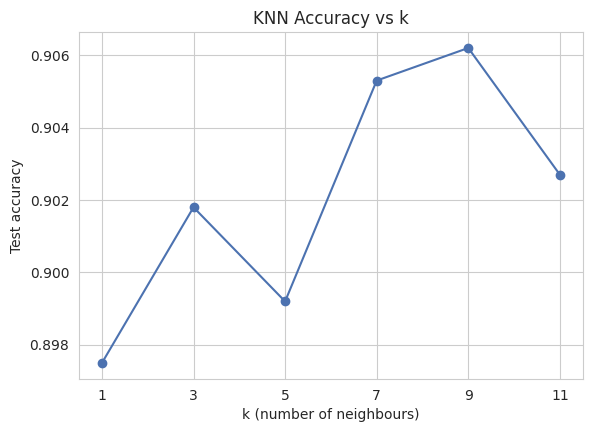

In [22]:
plt.figure(figsize=(6.5, 4.5))
plt.plot(knn_k.index, knn_k["Accuracy"], marker="o", color="#4C72B0")
plt.xlabel("k (number of neighbours)"); plt.ylabel("Test accuracy"); plt.title("KNN Accuracy vs k")
plt.xticks(knn_k.index)
plt.savefig("figures/fig_08_accuracy_vs_k.png", dpi=110, bbox_inches="tight")
plt.show()

*Inference:* Accuracy rises from 0.8975 at k = 1 to a peak of 0.9062 at k = 9 and then drops slightly at
k = 11. The curve is fairly flat, with the whole range spanning less than one percentage
point, so the model is not very sensitive to k in this range. The small dip at k = 1
reflects sensitivity to noisy neighbours, as predicted by the bias-variance trade-off.

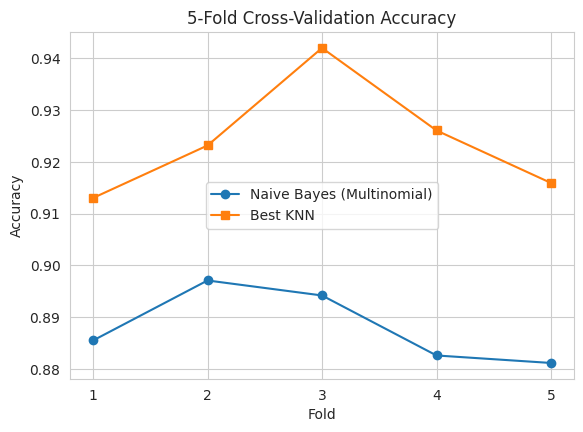

In [23]:
plt.figure(figsize=(6.5, 4.5))
plt.plot([1, 2, 3, 4, 5], nb_cv, marker="o", label="Naive Bayes (" + best_nb + ")")
plt.plot([1, 2, 3, 4, 5], knn_cv, marker="s", label="Best KNN")
plt.xlabel("Fold"); plt.ylabel("Accuracy"); plt.title("5-Fold Cross-Validation Accuracy"); plt.xticks([1, 2, 3, 4, 5]); plt.legend()
plt.savefig("figures/fig_09_cv_accuracy.png", dpi=110, bbox_inches="tight")
plt.show()

*Inference:* The KNN curve lies above the Naive Bayes curve in all five folds, by roughly 2 to 5
percentage points. Fold-to-fold variation is small for both models (a range of 0.88 to
0.94), which indicates that neither model's score depends strongly on the particular
training subset. KNN varies slightly more, peaking in fold 3 at 0.942.

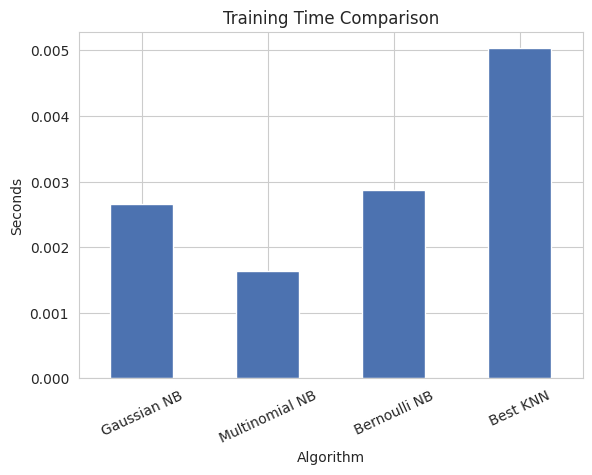

In [24]:
plt.figure(figsize=(6.5, 4.5))
time_df["Training(s)"].plot(kind="bar", color="#4C72B0")
plt.ylabel("Seconds"); plt.title("Training Time Comparison"); plt.xticks(rotation=25)
plt.savefig("figures/fig_10_training_time.png", dpi=110, bbox_inches="tight")
plt.show()

*Inference:* Training times are all in the millisecond range (about 2 to 6 ms), so training cost does not
separate the models. Gaussian NB is the cheapest to fit and the KNN is the most expensive
only because it builds a search tree. The absolute differences are tiny and affected by
timer noise.

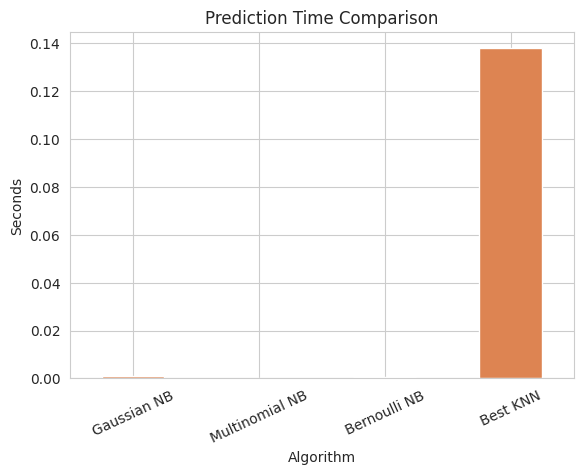

In [25]:
plt.figure(figsize=(6.5, 4.5))
time_df["Prediction(s)"].plot(kind="bar", color="#DD8452")
plt.ylabel("Seconds"); plt.title("Prediction Time Comparison"); plt.xticks(rotation=25)
plt.savefig("figures/fig_11_prediction_time.png", dpi=110, bbox_inches="tight")
plt.show()

*Inference:* Prediction time separates the models clearly: the three Naive Bayes variants take under 1
ms, while KNN takes roughly 0.15 s, over a hundred times longer than the slowest NB variant.
This gap would widen with more training data because KNN's query cost grows with n. This is
the main practical disadvantage of KNN for spam filtering at scale.

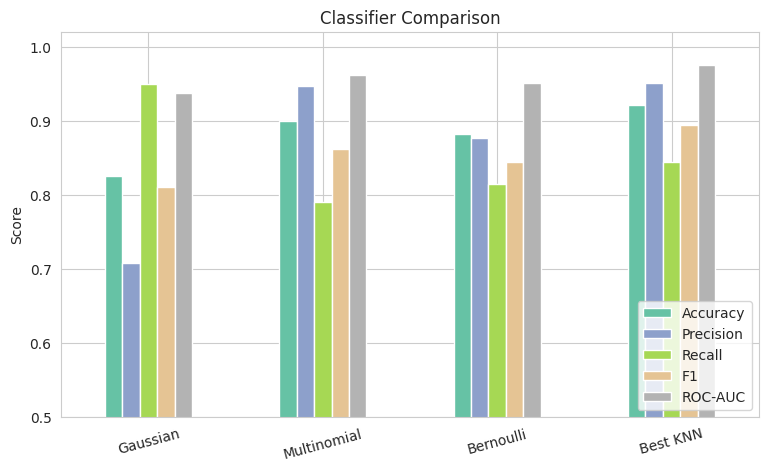

In [26]:
allr = nb_table.T.copy()
allr.loc["Best KNN"] = [knn_metrics[c] for c in allr.columns]
allr.plot(kind="bar", figsize=(9, 5), colormap="Set2")
plt.title("Classifier Comparison"); plt.ylabel("Score"); plt.ylim(0.5, 1.02); plt.legend(loc="lower right"); plt.xticks(rotation=15)
plt.savefig("figures/fig_12_classifier_comparison.png", dpi=110, bbox_inches="tight")
plt.show()

In [27]:
print(allr.round(4))

             Accuracy  Precision  Recall      F1  ROC-AUC
Gaussian       0.8254     0.7077  0.9493  0.8109   0.9368
Multinomial    0.9001     0.9472  0.7907  0.8619   0.9614
Bernoulli      0.8818     0.8768  0.8150  0.8447   0.9503
Best KNN       0.9209     0.9504  0.8436  0.8938   0.9754


*Inference:* The tuned KNN is best on accuracy (0.921), precision (0.950), F1 (0.894) and ROC-AUC
(0.975), Multinomial NB is the best Naive Bayes variant (accuracy 0.900) and Gaussian NB has
the best recall (0.949) but the worst precision. The differences between the best NB and the
KNN are about two percentage points of accuracy, so Naive Bayes is competitive given that it
is far cheaper to run. The best model depends on whether accuracy or prediction speed is the
priority.

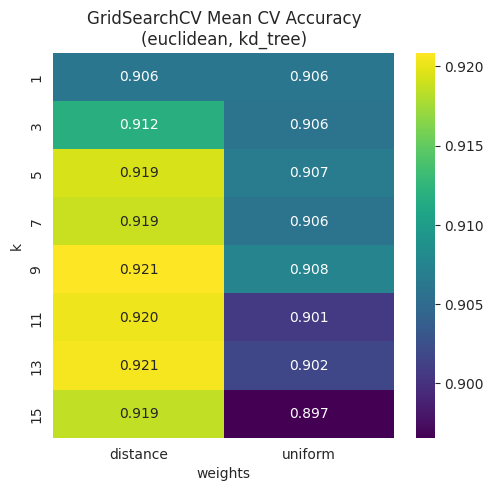

In [28]:
cvres = pd.DataFrame(grid.cv_results_)
sub = cvres[(cvres["param_metric"] == "euclidean") & (cvres["param_algorithm"] == "kd_tree")]
pv = sub.pivot_table(index="param_n_neighbors", columns="param_weights", values="mean_test_score")
plt.figure(figsize=(5.5, 5))
sns.heatmap(pv, annot=True, fmt=".3f", cmap="viridis")
plt.title("GridSearchCV Mean CV Accuracy\n(euclidean, kd_tree)"); plt.ylabel("k"); plt.xlabel("weights")
plt.savefig("figures/fig_13_gridsearch_heatmap.png", dpi=110, bbox_inches="tight")
plt.show()

*Inference:* Distance weighting is better than uniform weighting at every k from 3 upwards (for example
0.921 against 0.908 at k = 9). Accuracy with distance weighting rises from 0.906 at k = 1 to
a plateau of about 0.919 to 0.921 for k = 5 to 13, while uniform voting stays near 0.90 and
falls to 0.897 at k = 15. The plateau shows that the exact k is not critical once it exceeds
about 5 when neighbours are distance-weighted.

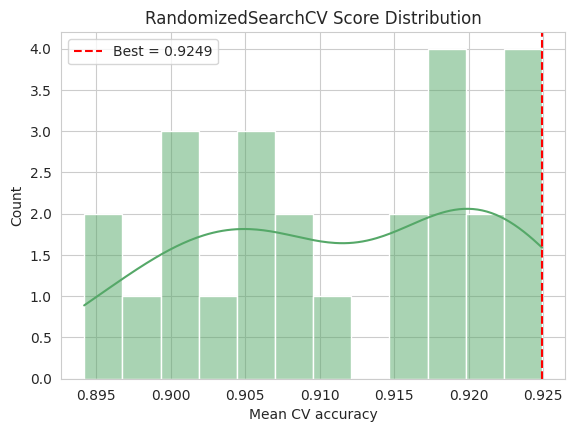

In [29]:
rr = pd.DataFrame(rand.cv_results_)
plt.figure(figsize=(6.5, 4.5))
sns.histplot(rr["mean_test_score"], bins=12, kde=True, color="#55A868")
plt.axvline(rand.best_score_, color="red", linestyle="--", label=f"Best = {rand.best_score_:.4f}")
plt.xlabel("Mean CV accuracy"); plt.title("RandomizedSearchCV Score Distribution"); plt.legend()
plt.savefig("figures/fig_14_randomsearch_distribution.png", dpi=110, bbox_inches="tight")
plt.show()

*Inference:* The 25 sampled configurations have mean CV accuracies between 0.894 and 0.925, with a median
of about 0.910, and the best (0.9249) is at the upper end of the distribution. The histogram
is skewed towards the high end, which means most random configurations are already close to
the optimum. This is why random search can match grid search with far fewer evaluations.

## Discussion

### Analysis Questions


1. Best Naive Bayes variant: Multinomial NB, with accuracy 0.900, precision 0.947, F1 0.862
and ROC-AUC 0.961, ahead of Bernoulli (0.882) and Gaussian (0.825). The features are non-
negative frequencies, which fit the multinomial event model better than a Gaussian
assumption.

2. Optimal k: GridSearchCV chose k = 13 (Manhattan, distance weighting, ball tree; CV
accuracy 0.9241), while RandomizedSearchCV found k = 6 with a CV accuracy of 0.9249. The
accuracy surface is flat for k between 5 and 13 with distance weighting, so any value in
that range is reasonable.

3. GridSearchCV against RandomizedSearchCV: grid search evaluated all 64 candidates in
roughly 20 to 25 s, random search evaluated 25 in roughly 10 to 12 s and obtained an equal
or slightly better score because it can sample values outside the grid. Grid search is
exhaustive and reproducible within its grid, whereas random search scales better to large
spaces.

4. KDTree against BallTree: both give identical accuracy (0.9209); BallTree was slightly
faster in this run (about 0.13 s against 0.17 s for prediction), but with 57 dimensions both
trees are close to brute force and the difference is within timing noise.

5. Theory against practice: the measured times follow the theoretical complexities, with
Naive Bayes predicting in under 1 ms (O(d) per sample) and KNN needing roughly 0.15 s
because each query searches the training set. The tree structures give little benefit at d =
57, which agrees with the curse of dimensionality.

6. Preferred classifier for large datasets: Naive Bayes, since its training is O(nd) and its
prediction is O(d) per sample independent of n, whereas KNN prediction cost grows with n.
KNN is more accurate here by about two points, so it is preferable when the dataset is small
and latency is not critical.

Strengths and limitations: KNN gives the best accuracy but is slow at query time; Naive
Bayes is fast but relies on independence. Possible improvements are feature selection, TF-
IDF style features, logistic regression or ensembles, and calibration of the decision
threshold to reduce false positives.

### Viva Questions


State Bayes theorem: P(C | X) = P(X | C) P(C) / P(X), the posterior probability of a class
given the evidence equals the likelihood times the prior divided by the evidence.

Gaussian against Multinomial NB: Gaussian NB models each continuous feature with a class-
specific normal distribution, whereas Multinomial NB models non-negative counts or
frequencies using class-specific category probabilities, which suits word-frequency data
(0.900 against 0.825 accuracy here).

Why normalise for KNN: KNN relies on distances, so a feature with a large numeric range
(such as `capital_run_length_total`, which reaches thousands) would dominate features
measured in fractions of a percent; standardisation gives each feature equal influence.

KDTree against BallTree: a KDTree splits space with axis-aligned hyperplanes and works best
in low dimensions, whereas a BallTree partitions the points into nested hyperspheres and
degrades more gracefully in higher dimensions or with non-axis-aligned structure; both
return exact neighbours.

## Conclusion


The experiment built and compared three Naive Bayes variants and a tuned KNN classifier on
the 4601-email Spambase dataset. Multinomial NB was the best Naive Bayes model (accuracy
0.900), while the KNN tuned by GridSearchCV (k = 13, Manhattan distance, distance weighting)
achieved the highest test accuracy (0.921) and ROC-AUC (0.975) and was confirmed by 5-fold
cross-validation (0.924 against 0.888). Randomised search matched grid search in less than
half the time, KDTree and BallTree gave identical accuracy, and the measured run times
agreed with the theoretical complexity: KNN predicts hundreds of times slower than Naive
Bayes. The choice therefore depends on the constraint: KNN for the best accuracy on moderate
data, Multinomial Naive Bayes for speed and scalability.

## References


[1] M. Hopkins, E. Reeber, G. Forman and J. Suermondt, "Spambase," UCI Machine Learning Repository, 1999. [Online]. Available: https://archive.ics.uci.edu/dataset/94/spambase

[2] F. Pedregosa et al., "Scikit-learn: Machine learning in Python," J. Mach. Learn. Res., vol. 12, pp. 2825-2830, 2011.

[3] T. Cover and P. Hart, "Nearest neighbor pattern classification," IEEE Trans. Inf. Theory, vol. 13, no. 1, pp. 21-27, 1967.

[4] A. McCallum and K. Nigam, "A comparison of event models for naive Bayes text classification," in AAAI-98 Workshop on Learning for Text Categorization, 1998, pp. 41-48.

[5] J. L. Bentley, "Multidimensional binary search trees used for associative searching," Commun. ACM, vol. 18, no. 9, pp. 509-517, 1975.

[6] J. Bergstra and Y. Bengio, "Random search for hyper-parameter optimization," J. Mach. Learn. Res., vol. 13, pp. 281-305, 2012.